In [1]:
import pathlib

print("Current working directory:", pathlib.Path().resolve())

Current working directory: /Users/lms/Documents/Forschung/textClust_hpo


In [2]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from moocore import hypervolume

from smac_hpo.evaluation.utils import build_results_csv, store_results_csv, load_results_csv, normalize, pareto_optimal_points 
from smac_hpo.evaluation.utils import COLORS, COLOR_PALETTE, ALGORITHM_ORDER, OLD_DATASETS, NEW_DATASETS, ALL_DATASETS, NUM_SEEDS, NUM_REPS
from smac_hpo.evaluation.utils import SINGLE_COLUMN_WIDTH, PANEL_HEIGHT, facet_aspect, set_publication_style
set_publication_style()

FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LATEX_DIR = pathlib.Path("latex")
LATEX_DIR.mkdir(parents=True, exist_ok=True )

In [3]:
HYPERPARAMETERS = {
    "FSD": [
        "model",
        "threshold",
        "window",
        "batch_size"
    ],
    "textClust": [
        "clean_interval",
        "cluster_interval",
        "decay_rate",
        "min_num_mc",
        "term_fading",
        "adaptive_threshold",
        "sigma",
        "radius",
        "threshold_momentum",
        "use_heuristic",
        "time_gap",
        "min_weight"
    ],
    "embClust": [
        "model", 
        "clean_interval",
        "cluster_interval",
        "decay_rate",
        "min_num_mc",
        "adaptive_threshold",
        "sigma",
        "radius",
        "threshold_momentum",
        "use_heuristic",
        "time_gap",
        "min_weight"
    ],
}
HYPERPARAMETERS_FLATTENED = list(set(param for params in HYPERPARAMETERS.values() for param in params))

In [4]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

In [5]:
config_performance = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()

config_performance_old_datasets = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & full_opt_results_df["dataset"].isin(OLD_DATASETS)].copy()

for _, group in config_performance.groupby(["dataset"]):
    config_performance.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values

for _, group in config_performance_old_datasets.groupby(["dataset"]):
    config_performance_old_datasets.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values


config_performance = (
    config_performance
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

config_performance_old_datasets = (
    config_performance_old_datasets
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

display(config_performance)
display(config_performance_old_datasets)

,config_id,algorithm,threshold,decay_rate,batch_size,radius,min_weight,time_gap,term_fading,clean_interval,window,threshold_momentum,adaptive_threshold,model,cluster_interval,use_heuristic,min_num_mc,sigma,adj_mutual_info_final,avg_throughput
0,FSD_best_config_loo_none_seed_1.json[0],FSD,0.500000,NaN,8.0,NaN,NaN,NaN,NaN,NaN,125.0,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,0.680219,0.645520
1,FSD_best_config_loo_none_seed_1.json[1],FSD,0.514959,NaN,9.0,NaN,NaN,NaN,NaN,NaN,116.0,NaN,NaN,minishlab_4M,NaN,NaN,NaN,NaN,0.497164,0.962960
2,FSD_best_config_loo_none_seed_1.json[2],FSD,0.306805,NaN,25.0,NaN,NaN,NaN,NaN,NaN,59.0,NaN,NaN,minishlab_4M,NaN,NaN,NaN,NaN,0.319218,0.976516
3,FSD_best_config_loo_none_seed_1.json[3],FSD,0.584279,NaN,3.0,NaN,NaN,NaN,NaN,NaN,76.0,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,0.716483,0.642982
4,FSD_best_config_loo_none_seed_1.json[4],FSD,0.586306,NaN,29.0,NaN,NaN,NaN,NaN,NaN,78.0,NaN,NaN,minishlab_8M,NaN,NaN,NaN,NaN,0.474775,0.957480
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,NaN,0.000236,NaN,NaN,7.137730,NaN,1.0,400.0,NaN,0.234695,1.0,NaN,4888.0,0.0,2.0,0.263364,0.627966,0.920698
142,textClust_best_config_loo_none_seed_9.json[5],textClust,NaN,0.021127,NaN,NaN,1.938501,NaN,1.0,227.0,NaN,0.079436,1.0,NaN,4925.0,0.0,9.0,0.266890,0.664263,0.951646
143,textClust_best_config_loo_none_seed_9.json[6],textClust,NaN,0.011202,NaN,NaN,3.097142,NaN,0.0,114.0,NaN,0.025919,1.0,NaN,4953.0,0.0,2.0,0.121910,0.646849,0.811976
144,textClust_best_config_loo_none_seed_9.json[7],textClust,NaN,0.011370,NaN,NaN,4.407335,NaN,0.0,116.0,NaN,0.010312,1.0,NaN,4957.0,0.0,2.0,0.145887,0.691339,0.821548


,config_id,algorithm,threshold,decay_rate,batch_size,radius,min_weight,time_gap,term_fading,clean_interval,window,threshold_momentum,adaptive_threshold,model,cluster_interval,use_heuristic,min_num_mc,sigma,adj_mutual_info_final,avg_throughput
0,FSD_best_config_loo_none_seed_1.json[0],FSD,0.500000,NaN,8.0,NaN,NaN,NaN,NaN,NaN,125.0,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,0.741515,0.694088
1,FSD_best_config_loo_none_seed_1.json[1],FSD,0.514959,NaN,9.0,NaN,NaN,NaN,NaN,NaN,116.0,NaN,NaN,minishlab_4M,NaN,NaN,NaN,NaN,0.638557,0.955922
2,FSD_best_config_loo_none_seed_1.json[2],FSD,0.306805,NaN,25.0,NaN,NaN,NaN,NaN,NaN,59.0,NaN,NaN,minishlab_4M,NaN,NaN,NaN,NaN,0.477592,0.971194
3,FSD_best_config_loo_none_seed_1.json[3],FSD,0.584279,NaN,3.0,NaN,NaN,NaN,NaN,NaN,76.0,NaN,NaN,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,0.716279,0.691229
4,FSD_best_config_loo_none_seed_1.json[4],FSD,0.586306,NaN,29.0,NaN,NaN,NaN,NaN,NaN,78.0,NaN,NaN,minishlab_8M,NaN,NaN,NaN,NaN,0.668250,0.962013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,NaN,0.000236,NaN,NaN,7.137730,NaN,1.0,400.0,NaN,0.234695,1.0,NaN,4888.0,0.0,2.0,0.263364,0.762790,0.922767
142,textClust_best_config_loo_none_seed_9.json[5],textClust,NaN,0.021127,NaN,NaN,1.938501,NaN,1.0,227.0,NaN,0.079436,1.0,NaN,4925.0,0.0,9.0,0.266890,0.593075,0.952992
143,textClust_best_config_loo_none_seed_9.json[6],textClust,NaN,0.011202,NaN,NaN,3.097142,NaN,0.0,114.0,NaN,0.025919,1.0,NaN,4953.0,0.0,2.0,0.121910,0.496894,0.757937
144,textClust_best_config_loo_none_seed_9.json[7],textClust,NaN,0.011370,NaN,NaN,4.407335,NaN,0.0,116.0,NaN,0.010312,1.0,NaN,4957.0,0.0,2.0,0.145887,0.527019,0.765395


In [6]:
def prepare_dataset(full_df, algorithm):
    df = full_df.copy()
    df = df[df["algorithm"] == algorithm]

    df = df[["adj_mutual_info_final", "avg_throughput", "config_id"] + HYPERPARAMETERS[algorithm]]
    df = df.dropna(axis=1, how="any")
    
    config_ids = df["config_id"]
    df = df.drop(columns=["config_id"])
    if np.any(df.dtypes == "str"):
        df = pd.get_dummies(df, columns=df.columns[df.dtypes == "str"], drop_first=True)
    df = df.astype(float)

    # Min-max normalization for each hyperparameter
    df = (df - df.min()) / (df.max() - df.min())

    y = df[["adj_mutual_info_final", "avg_throughput"]].values
    X = df.drop(columns=["adj_mutual_info_final", "avg_throughput"])
    X.loc[:, "config_id"] = config_ids
    
    return X, y

In [7]:
from sklearn.model_selection import ParameterGrid
import numpy as np
import smac_hpo.evaluation.evolutionary_clustering as evolutionary_clustering
from sklearn.metrics import silhouette_score
from tqdm import tqdm
from sklearn.decomposition import PCA

def grid_search(X, y, objective_weight=0.5, decision_weight=0.5):
    weights = np.array([objective_weight, decision_weight], dtype=float)
    if np.any(weights < 0) or weights.sum() == 0:
        raise ValueError("Weights must be non-negative and at least one must be positive.")
    weights /= weights.sum()

    X = X.drop(columns=["config_id"]).copy()
    params = {
        "dim": list(range(1,X.shape[1])),
        "n_clusters": list(range(2,10))
    }

    best = None
    best_metric = 0.0

    for param in tqdm(ParameterGrid(params)):
        dim = param["dim"]
        n_clusters = param["n_clusters"]
        
        X_low_dim = PCA(n_components=dim).fit_transform(X)
        
        best_labels = evolutionary_clustering.evolutionary_multi_space_clustering(
            X_low_dim, y,
            generations=500,
            n_clusters=n_clusters,
            random_state=42)
        
        objective_silhouette = silhouette_score(y, best_labels)
        decision_silhouette = silhouette_score(X_low_dim, best_labels)
        objective_score = (objective_silhouette + 1) / 2
        decision_score = (decision_silhouette + 1) / 2
        score_sum = objective_score + decision_score
        mean = 0.0 if score_sum == 0 else 2 * objective_score * decision_score / score_sum
        if mean > best_metric:
            print(f"Found new best: {mean}, {param}")
            best_metric = mean
            best = param
            
    assert best is not None, "No configuration found!"        
    print(f"Best configuration: {best} ({best_metric})")
    return best, best_metric

In [8]:
def evaluate(X,y,best_config):
    X_low_dim = PCA(n_components=best_config["dim"]).fit_transform(X.drop(columns=["config_id"]))
    best_labels = evolutionary_clustering.evolutionary_multi_space_clustering(
        X_low_dim, y,
        generations=500,
        n_clusters=best_config["n_clusters"],
        random_state=42)

    print("Decision-space silhouette:", silhouette_score(X_low_dim, best_labels))
    print("Objective-space silhouette:", silhouette_score(y, best_labels))
    print("Mean silhouette:", (silhouette_score(y, best_labels) + silhouette_score(X_low_dim, best_labels))/2)
    df_config = X.copy()
    df_config["cluster"] = best_labels

    df_performance = pd.DataFrame(y.copy(), columns=["adj_mutual_info_final", "avg_throughput"])
    df = df_config.copy()
    df.loc[:, df_performance.columns] = df_performance.values
    return df

In [9]:
DO_GRID_SEARCH = False

best_configs = {
    "FSD": {'dim': 3, 'n_clusters': 2},
    "embClust" : {'dim': 1, 'n_clusters': 2},
    "textClust" : {'dim': 6, 'n_clusters': 2}
}

result = []
for alg in ["FSD", "embClust", "textClust"]:
    X,y = prepare_dataset(config_performance, alg)
    if DO_GRID_SEARCH:
        best, _ = grid_search(X, y)
    else:
        best = best_configs[alg]
    df = evaluate(X,y,best)
    df["algorithm"] = alg
    result.append(df)
    
cluster_results = pd.concat(result)

cluster_centroids = cluster_results.copy()
cluster_centroids = (
    cluster_centroids.drop(columns="config_id").groupby(["algorithm", "cluster"])
    .mean()   
    .reset_index() 
)
cluster_centroids
    

Decision-space silhouette: 0.40943004717481657
Objective-space silhouette: 0.5816096049732083
Mean silhouette: 0.49551982607401246
Decision-space silhouette: 0.6197309827218555
Objective-space silhouette: 0.37844922880913745
Mean silhouette: 0.49909010576549645
Decision-space silhouette: 0.2954401368423174
Objective-space silhouette: 0.6534694503947288
Mean silhouette: 0.4744547936185231


,algorithm,cluster,threshold,window,batch_size,model_Mihaiii_gte_micro_v4,model_MongoDB,model_NeuML,model_Snowflake,model_intfloat,...,model_sentence_transformers_all_MiniLM_L6_v2,adj_mutual_info_final,avg_throughput,clean_interval,cluster_interval,decay_rate,min_num_mc,adaptive_threshold,use_heuristic,term_fading
0,FSD,0,0.411948,0.321347,0.028376,0.00000,0.00000,0.000000,0.083333,0.000000,...,0.916667,0.884344,0.066379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FSD,1,0.506639,0.385845,0.147783,0.02381,0.02381,0.166667,0.000000,0.047619,...,0.000000,0.420800,0.825352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,embClust,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.095238,0.629911,0.716698,0.579223,0.231781,0.110532,0.275862,1.000000,0.761905,NaN
3,embClust,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.086957,0.320535,0.858767,0.643693,0.460224,0.193299,0.490255,0.782609,0.608696,NaN
4,textClust,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.860993,0.569276,0.438073,0.392386,0.231625,0.156469,1.000000,0.409091,0.727273
5,textClust,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.106732,0.903626,0.165966,0.614336,0.305762,0.548077,0.000000,0.000000,0.500000


In [10]:
df = cluster_centroids.copy()

for alg in ["FSD", "embClust", "textClust"]:
    subset = df[df["algorithm"] == alg]
    subset = subset.drop(columns=["algorithm", "cluster"])
    subset = (subset
                .diff()
                .iloc[-1, :]
                .transpose()
                .abs()
                .sort_values(ascending = False))
    display(subset)


model_sentence_transformers_all_MiniLM_L6_v2    0.916667
avg_throughput                                  0.758972
adj_mutual_info_final                           0.463544
model_minishlab_4M                              0.309524
model_minishlab_2M                              0.190476
model_NeuML                                     0.166667
model_minishlab_8M                              0.142857
batch_size                                      0.119407
threshold                                       0.094691
model_Snowflake                                 0.083333
model_minishlab_32M                             0.071429
window                                          0.064498
model_intfloat                                  0.047619
model_Mihaiii_gte_micro_v4                      0.023810
model_MongoDB                                   0.023810
clean_interval                                       NaN
cluster_interval                                     NaN
decay_rate                     

model_minishlab_32M                             0.904762
adj_mutual_info_final                           0.309376
model_minishlab_2M                              0.260870
cluster_interval                                0.228443
model_minishlab_8M                              0.217391
adaptive_threshold                              0.217391
min_num_mc                                      0.214393
model_minishlab_4M                              0.173913
use_heuristic                                   0.153209
avg_throughput                                  0.142069
decay_rate                                      0.082767
clean_interval                                  0.064470
model_sentence_transformers_all_MiniLM_L6_v2    0.008282
threshold                                            NaN
window                                               NaN
batch_size                                           NaN
model_Mihaiii_gte_micro_v4                           NaN
model_MongoDB                  

adaptive_threshold                              1.000000
adj_mutual_info_final                           0.754261
use_heuristic                                   0.409091
min_num_mc                                      0.391608
avg_throughput                                  0.334350
clean_interval                                  0.272107
term_fading                                     0.227273
cluster_interval                                0.221950
decay_rate                                      0.074137
threshold                                            NaN
window                                               NaN
batch_size                                           NaN
model_Mihaiii_gte_micro_v4                           NaN
model_MongoDB                                        NaN
model_NeuML                                          NaN
model_Snowflake                                      NaN
model_intfloat                                       NaN
model_minishlab_2M             

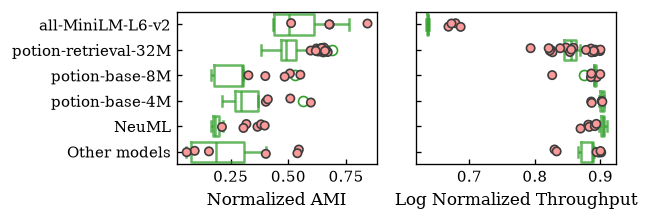

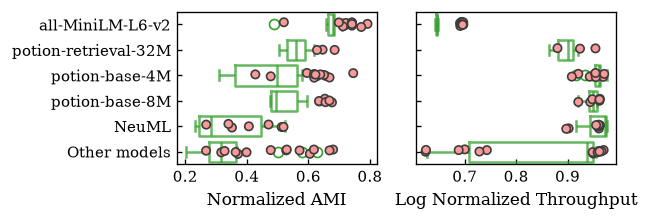

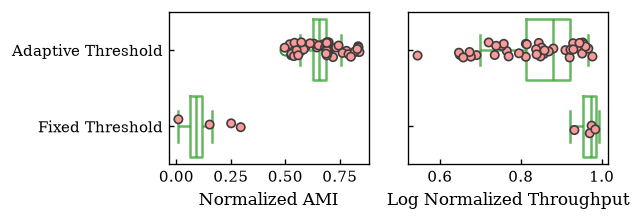

In [11]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def make_boxplots(data, data_old, algorithm, cat_column):
    df = data.copy()
    df_old = data_old.copy()
    
    df = (df
        .merge(cluster_results[["config_id", "cluster"]])
        .loc[df["algorithm"] == algorithm, ["config_id", "adj_mutual_info_final", "avg_throughput"]+[cat_column]]
        .sort_values(by="config_id"))
    
    df_sorting = (-1 * df["adj_mutual_info_final"]).argsort()
    df = df.iloc[df_sorting,:]
    
    df_old = (df_old
            .merge(cluster_results[["config_id", "cluster"]])
            .loc[df_old["algorithm"] == algorithm, ["config_id", "adj_mutual_info_final", "avg_throughput"]+[cat_column]]
            .sort_values(by="config_id"))
    
    df_old = df_old.iloc[df_sorting,:]
    
    fig, ax = plt.subplots(1,2, sharey=True, figsize=(SINGLE_COLUMN_WIDTH, PANEL_HEIGHT*0.7))
    
    df_old.loc[:,"dataset_source"] = "Test"
    df.loc[:,"dataset_source"] = "Train"  
    
    palette={
        "Train": sns.color_palette("Paired", n_colors=5)[3],
        "Test": sns.color_palette("Paired", n_colors=5)[4]
    }
    
    order = (df
             .groupby(cat_column)["adj_mutual_info_final"]
             .median()
             .sort_values(ascending=False)
             .reset_index()[cat_column])
    order = order[order.str.contains("Other").argsort()]
        
    sns.boxplot(df, x = "adj_mutual_info_final", y=cat_column, ax=ax[0], 
                color=palette["Train"], fill=False,
                boxprops={"alpha": 0.75},
                whiskerprops={"alpha": 0.75},
                capprops={"alpha": 0.75},
                medianprops={"alpha": 0.75},
                order = order
                )
    sns.stripplot(pd.concat([df_old]), x = "adj_mutual_info_final", y=cat_column, ax=ax[0], 
                hue="dataset_source", palette=palette, dodge=True, linewidth=1, size=5,
                order=order)

    sns.boxplot(df, x = "avg_throughput", y=cat_column, ax=ax[1], 
                color=palette["Train"], fill=False,
                boxprops={"alpha": 0.75},
                whiskerprops={"alpha": 0.75},
                capprops={"alpha": 0.75},
                medianprops={"alpha": 0.75},
                order = order
                )
    sns.stripplot(pd.concat([df_old]), x = "avg_throughput", y=cat_column, ax=ax[1], 
                hue="dataset_source", palette=palette, dodge=True, linewidth=1,
                order=order)

    ax[0].set_xlabel("Normalized AMI")
    ax[1].set_xlabel("Log Normalized Throughput")

    
    handles = [
        Patch(facecolor="none", edgecolor=palette["Train"], linewidth=1.5, alpha=0.75,
            label="Train"),
        Line2D([], [], marker="o", linestyle="None", markerfacecolor=palette["Test"], markeredgecolor="black", markersize=6,
            label="Test"),
    ]
    legend_fig = plt.figure()
    legend_fig.legend(handles=handles, loc="center", ncol=2)
    legend_fig.savefig(
        FIGURES_DIR / "config_analysis_train_test_legend.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0,
    )
    plt.close(legend_fig)

    for a in ax:
        a.get_legend().remove()
        a.set_ylabel("")

    fig.savefig(
        FIGURES_DIR / f"config_analysis_{algorithm}_{cat_column}.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.1,
    )

model_name_mapping = {
    "sentence_transformers_all_MiniLM_L6_v2": "all-MiniLM-L6-v2",
    "minishlab_32M": "potion-retrieval-32M",
    "minishlab_4M": "potion-base-4M",
    "minishlab_8M": "potion-base-8M",
    "NeuML" : "NeuML"
}

data = config_performance.copy()
data["model_name"] = (
    data["model"]
    .map(model_name_mapping)
    .fillna("Other models")
)

data_old = config_performance_old_datasets.copy()
data_old["model_name"] = (
    data_old["model"]
    .map(model_name_mapping)
    .fillna("Other models")
)


make_boxplots(data, data_old, "embClust", "model_name")
make_boxplots(data, data_old, "FSD", "model_name")

data = config_performance.copy()
data_old = config_performance_old_datasets.copy()

data.loc[:,"term_fading_cat"] = np.where(data["adaptive_threshold"], "Adaptive Threshold", "Fixed Threshold")
data_old.loc[:,"term_fading_cat"] = np.where(data_old["adaptive_threshold"], "Adaptive Threshold", "Fixed Threshold")

make_boxplots(data, data_old, "textClust", "term_fading_cat")